In [1]:
import matplotlib
print(matplotlib.__version__)

3.10.0


## 1. ติดตั้งไลบรารีและนำเข้าโมดูลที่จำเป็น (Setup & Imports)

โน้ตบุ๊กนี้ออกแบบให้รันบน **Kaggle Notebook** หรือ **Google Colab** (แนะนำให้เปิดใช้ GPU: Kaggle → Settings → Accelerator → GPU,
Colab → Runtime → Change runtime type → GPU) เนื่องจากต้องฝึกโมเดล Deep Learning หลายตัว

ถ้ารันบนเครื่องตัวเอง ให้ติดตั้งไลบรารีด้านล่างก่อน (บน Kaggle/Colab ส่วนใหญ่ติดตั้งไว้ให้แล้ว)

In [2]:
!pip install -q tensorflow kagglehub opencv-python-headless scikit-learn seaborn tqdm

In [ ]:
import sys
import numpy as np

print("Python:", sys.executable)
print("NumPy:", np.__version__)

Python: /usr/bin/python3
NumPy: 2.1.3


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.10.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os
import gc
import json
import random
import shutil
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import (
    vgg16, resnet50, densenet, efficientnet, mobilenet_v2
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

print("TensorFlow version :", tf.__version__)
print("GPU available      :", tf.config.list_physical_devices("GPU"))

TensorFlow version : 2.20.0
GPU available      : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# แหล่งข้อมูลที่ 1: AI vs Real videos - Animals
ANIMAL_DIR = get_dataset_path(
    kaggle_input_name="ai-vs-real-videos-dataset-animals",
    kagglehub_slug="khan4568/ai-vs-real-videos-dataset-animals",
)

# แหล่งข้อมูลที่ 2: AI vs Real videos - Human activity
HUMAN_DIR = get_dataset_path(
    kaggle_input_name="ai-vs-real-videos-dataset-human-activity",
    kagglehub_slug="khan4568/ai-vs-real-videos-dataset-human-activity",
)

print("ANIMAL_DIR:", ANIMAL_DIR)
print("HUMAN_DIR :", HUMAN_DIR)

NameError: name 'get_dataset_path' is not defined

## 2. ตั้งค่าพารามิเตอร์หลัก (Configuration)

รวมค่าคงที่ทั้งหมดไว้ที่เดียว เพื่อให้ปรับแก้ได้ง่าย เช่น ขนาดภาพ, batch size, จำนวน epoch, จำนวนภาพต่อแหล่งข้อมูล ฯลฯ

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CONFIG = {
    # ----- ข้อมูล -----
    "IMG_SIZE": 224,
    "N_FRAMES_PER_VIDEO": 12,
    "DOMAINS": ["animal", "human"],
    "CLASS_NAMES": ["FAKE", "REAL"],
    "TRAIN_RATIO": 0.70,
    "VAL_RATIO": 0.15,
    "TEST_RATIO": 0.15,

    # ----- การฝึกโมเดล -----
    "BATCH_SIZE": 32,
    "EPOCHS_HEAD": 8,
    "EPOCHS_FINETUNE": 6,
    "LEARNING_RATE": 1e-3,
    "FINETUNE_LR": 1e-5,

    # ----- path -----
    "SPLIT_DIR": Path("data"),
    "OUTPUT_DIR": Path("outputs"),
}

for p in [CONFIG["SPLIT_DIR"], CONFIG["OUTPUT_DIR"]]:
    p.mkdir(parents=True, exist_ok=True)

CONFIG

{'IMG_SIZE': 224,
 'N_FRAMES_PER_VIDEO': 12,
 'DOMAINS': ['animal', 'human'],
 'CLASS_NAMES': ['FAKE', 'REAL'],
 'TRAIN_RATIO': 0.7,
 'VAL_RATIO': 0.15,
 'TEST_RATIO': 0.15,
 'BATCH_SIZE': 32,
 'EPOCHS_HEAD': 8,
 'EPOCHS_FINETUNE': 6,
 'LEARNING_RATE': 0.001,
 'FINETUNE_LR': 1e-05,
 'SPLIT_DIR': WindowsPath('data'),
 'OUTPUT_DIR': WindowsPath('outputs')}

## 3. ดาวน์โหลดชุดข้อมูลจาก Kaggle (Dataset Acquisition)

โปรเจกต์นี้ใช้ 2 ชุดข้อมูลจาก Kaggle:

1. **Fake or Real Competition Dataset** — `kidonpark1023/fake-or-real-dataset`
2. **CIFAKE: Real and AI-Generated Synthetic Images** — `birdy654/cifake-real-and-ai-generated-synthetic-images`

**วิธีที่ 1 — รันบน Kaggle Notebook (แนะนำ):**
ไปที่แท็บ *Add Input* แล้วเพิ่มชุดข้อมูลทั้งสองชื่อข้างต้น ระบบจะ mount ให้อัตโนมัติที่ `/kaggle/input/...`
โค้ดด้านล่างตรวจสอบให้อัตโนมัติว่ากำลังรันบน Kaggle หรือไม่ ถ้าใช่จะใช้ path นี้ทันที (ไม่ต้องดาวน์โหลดซ้ำ)

**วิธีที่ 2 — รันบนเครื่องอื่น / Colab:** ใช้ไลบรารี `kagglehub` (ต้องตั้งค่า Kaggle API token ก่อน
ดู https://github.com/Kaggle/kagglehub#authenticate)

In [ ]:
def get_dataset_path(kaggle_input_name: str, kagglehub_slug: str) -> Path:
    """คืน path ไปยังชุดข้อมูล โดยเช็คก่อนว่ารันบน Kaggle Notebook หรือไม่
    ถ้าไม่ใช่ จะดาวน์โหลดผ่าน kagglehub แทน"""
    kaggle_path = Path("/kaggle/input") / kaggle_input_name
    if kaggle_path.exists():
        print(f"[OK] พบข้อมูลบน Kaggle input: {kaggle_path}")
        return kaggle_path

    try:
        import kagglehub
        path = Path(kagglehub.dataset_download(kagglehub_slug))
        print(f"[OK] ดาวน์โหลดผ่าน kagglehub ไปที่: {path}")
        return path
    except Exception as e:
        raise RuntimeError(
            f"ไม่พบข้อมูลใน /kaggle/input และดาวน์โหลดผ่าน kagglehub ไม่สำเร็จ ({e}).\n"
            "กรุณา Add Input บน Kaggle หรือดาวน์โหลดชุดข้อมูลด้วยตนเองแล้วแก้ path"
        )


# # แหล่งข้อมูลที่ 1: Fake or Real Competition Dataset
# FAKE_OR_REAL_DIR = get_dataset_path(
#     kaggle_input_name="fake-or-real-dataset",
#     kagglehub_slug="kidonpark1023/fake-or-real-dataset",
# )

# # แหล่งข้อมูลที่ 2: CIFAKE
# CIFAKE_DIR = get_dataset_path(
#     kaggle_input_name="cifake-real-and-ai-generated-synthetic-images",
#     kagglehub_slug="birdy654/cifake-real-and-ai-generated-synthetic-images",
# )

# print("\nFAKE_OR_REAL_DIR:", FAKE_OR_REAL_DIR)
# print("CIFAKE_DIR      :", CIFAKE_DIR)

# แหล่งข้อมูลที่ 1: AI vs Real videos - Animals
ANIMAL_DIR = get_dataset_path(
    kaggle_input_name="ai-vs-real-videos-dataset-animals",
    kagglehub_slug="khan4568/ai-vs-real-videos-dataset-animals",
)

# แหล่งข้อมูลที่ 2: AI vs Real videos - Human activity
HUMAN_DIR = get_dataset_path(
    kaggle_input_name="ai-vs-real-videos-dataset-human-activity",
    kagglehub_slug="khan4568/ai-vs-real-videos-dataset-human-activity",
)

print("ANIMAL_DIR:", ANIMAL_DIR)
print("HUMAN_DIR :", HUMAN_DIR)

100%|██████████| 4.62G/4.62G [02:01<00:00, 40.7MB/s]

Extracting files...


[OK] ดาวน์โหลดผ่าน kagglehub ไปที่: /root/.cache/kagglehub/datasets/khan4568/ai-vs-real-videos-dataset-animals/versions/1


100%|██████████| 5.36G/5.36G [02:27<00:00, 39.1MB/s]

Extracting files...


[OK] ดาวน์โหลดผ่าน kagglehub ไปที่: /root/.cache/kagglehub/datasets/khan4568/ai-vs-real-videos-dataset-human-activity/versions/1
ANIMAL_DIR: /root/.cache/kagglehub/datasets/khan4568/ai-vs-real-videos-dataset-animals/versions/1
HUMAN_DIR : /root/.cache/kagglehub/datasets/khan4568/ai-vs-real-videos-dataset-human-activity/versions/1


In [ ]:
def preview_folder_structure(root: Path, max_depth=3, max_items=8):
    """แสดงโครงสร้างโฟลเดอร์คร่าว ๆ เพื่อให้รู้ว่าต้องเขียนตัวจับคู่ REAL/FAKE อย่างไร"""
    root = Path(root)
    print(f"โครงสร้างของ: {root}")
    for depth_dir, dirs, files in os.walk(root):
        depth = len(Path(depth_dir).relative_to(root).parts)
        if depth > max_depth:
            continue
        indent = "  " * depth
        print(f"{indent}{Path(depth_dir).name}/  ({len(files)} files)")
        for f in files[:max_items]:
            print(f"{indent}  - {f}")
        if len(files) > max_items:
            print(f"{indent}  ... และอีก {len(files) - max_items} ไฟล์")


preview_folder_structure(ANIMAL_DIR)
print("\n" + "=" * 60 + "\n")
preview_folder_structure(HUMAN_DIR)

โครงสร้างของ: /root/.cache/kagglehub/datasets/khan4568/ai-vs-real-videos-dataset-animals/versions/1
1/  (0 files)
  AI Animals/  (0 files)
    Bears/  (25 files)
      - sora-video-1757499239246.mp4
      - 20250910_1325_Bears Tranquil Forage_simple_compose_01k4sjhptvf9tsn73w5rq7wf78.mp4
      - sora-video-1757498988601.mp4
      - sora-video-1757498785101.mp4
      - Scene 80.mp4
      - sora-video-1757498936530.mp4
      - 20250910_1305_Polar Bear s Arctic Expedition_simple_compose_01k4shbncmervrsvew4cjnyg3a.mp4
      - wildnature_al_1024p_20250914_020047.mp4
      ... และอีก 17 ไฟล์
    Deer/  (25 files)
      - 20250912_0347_Serene Woodland Deer_simple_compose_01k4xp7cehfy585czphrnb2kex.mp4
      - sora-video-1757729323269.mp4
      - wildnature_al_854p_20250914_021034.mp4
      - _deer_drinking_202510301248_9bv5m.mp4
      - assets_task_01jjvaz2hqegaafvv1qmac1c49_task_01jjvaz2hqegaafvv1qmac1c49_genid_721cfd3d-361c-44fe-9015-87968f44104f_25_01_30_10_10_649437_videos_00000_48497252_

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 4. รวมและสุ่มตัวอย่างข้อมูลเป็นชุดข้อมูลเดียว (Unify Dataset)

ขั้นตอนนี้จะ:
1. ค้นหาไฟล์ภาพทั้งหมดในแต่ละแหล่งข้อมูล แล้วจัดกลุ่มเป็น REAL / FAKE ตามชื่อโฟลเดอร์
2. สุ่ม (with fixed seed) ภาพจากแต่ละ (แหล่งข้อมูล x คลาส) มาอย่างละ `N_PER_SOURCE` ภาพ (ค่าเริ่มต้น 2,500)
3. คัดลอกภาพทั้งหมดไปรวมไว้ที่ `data/raw/REAL` และ `data/raw/FAKE`

ผลลัพธ์สุดท้าย: REAL 5,000 ภาพ (2,500 จากแต่ละแหล่ง) + FAKE 5,000 ภาพ (2,500 จากแต่ละแหล่ง) รวม 10,000 ภาพ

In [ ]:
VIDEO_EXTS = {".mp4", ".mov", ".avi", ".webm", ".mkv"}

REAL_DIR_NAMES = {"real animals", "real human activity"}
FAKE_DIR_NAMES = {"ai animals", "ai human activity"}

def find_videos_by_class(root: Path):
    """เดินสำรวจไฟล์วิดีโอใต้ root แล้วจัดเข้ากลุ่ม REAL / FAKE จากชื่อโฟลเดอร์แม่"""
    buckets = {"REAL": [], "FAKE": []}
    root = Path(root)
    for path in root.rglob("*"):
        if path.suffix.lower() not in VIDEO_EXTS or not path.is_file():
            continue
        # .strip() ตรงนี้สำคัญ เพราะโฟลเดอร์บางชื่อมีช่องว่างนำหน้า/ตามหลังปนมา
        # เช่น " Real Human activity" ถ้าไม่ strip จะไม่ match กับ "real human activity" เลย
        path_parts_lower = [part.strip().lower() for part in path.parts]
        has_real_dir = any(name in path_parts_lower for name in REAL_DIR_NAMES)
        has_fake_dir = any(name in path_parts_lower for name in FAKE_DIR_NAMES)
        if has_real_dir and not has_fake_dir:
            buckets["REAL"].append(path)
        elif has_fake_dir and not has_real_dir:
            buckets["FAKE"].append(path)
    return buckets


domain_sources = {
    "animal": find_videos_by_class(ANIMAL_DIR),
    "human": find_videos_by_class(HUMAN_DIR),
}

print("จำนวนวิดีโอที่หาเจอในแต่ละโดเมน:")
_problem = []
for dom, buckets in domain_sources.items():
    n_real, n_fake = len(buckets["REAL"]), len(buckets["FAKE"])
    print(f"  {dom:10s}  REAL={n_real:5d}   FAKE={n_fake:5d}")
    if n_real == 0 or n_fake == 0:
        _problem.append(dom)

if _problem:
    raise RuntimeError(f"โดเมนต่อไปนี้หาไฟล์ REAL หรือ FAKE ไม่เจอเลย: {_problem}")

จำนวนวิดีโอที่หาเจอในแต่ละโดเมน:
  animal      REAL=  500   FAKE=  500
  human       REAL=  500   FAKE=  500


Cell: stratified split ที่ระดับวิดีโอ (ก่อนตัดเฟรม — กันไฟล์เดียวกันหลุดข้าม split)

In [ ]:
def split_video_list(paths, train_ratio, val_ratio, seed):
    paths = sorted(paths)  # sort ก่อนสุ่ม ให้ reproducible ไม่ขึ้นกับลำดับ os คืนมา
    rng = random.Random(seed)
    rng.shuffle(paths)
    n = len(paths)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)
    return {
        "train": paths[:n_train],
        "val": paths[n_train:n_train + n_val],
        "test": paths[n_train + n_val:],
    }

# แบ่งแยกทั้ง 4 กลุ่ม (animal-real, animal-fake, human-real, human-fake) อิสระต่อกัน
video_splits = {"train": [], "val": [], "test": []}  # แต่ละ item: (path, class, domain)

for dom, buckets in domain_sources.items():
    for cls, paths in buckets.items():
        split = split_video_list(paths, CONFIG["TRAIN_RATIO"], CONFIG["VAL_RATIO"], SEED)
        for split_name, split_paths in split.items():
            for p in split_paths:
                video_splits[split_name].append((p, cls, dom))

for split_name, items in video_splits.items():
    n_real = sum(1 for _, c, _ in items if c == "REAL")
    n_fake = sum(1 for _, c, _ in items if c == "FAKE")
    print(f"{split_name:6s}: REAL={n_real:5d}  FAKE={n_fake:5d}  total={len(items)}")

train : REAL=  700  FAKE=  700  total=1400
val   : REAL=  150  FAKE=  150  total=300
test  : REAL=  150  FAKE=  150  total=300


Cell: ตัดเฟรมจากวิดีโอตาม split ที่แบ่งไว้แล้ว

In [ ]:
import cv2

CONFIG["N_FRAMES_PER_VIDEO"] = 12  # ปรับได้ตามที่คุยกัน (10-15 เหมาะสม)

def extract_frames_to_disk(video_path: Path, out_dir: Path, stem: str, n_frames: int, img_size: int):
    cap = cv2.VideoCapture(str(video_path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    saved = 0
    if total <= 0:
        cap.release()
        return saved
    idxs = [int(total * f / (n_frames + 1)) for f in range(1, n_frames + 1)]
    for i, idx in enumerate(idxs):
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if not ok:
            continue
        frame = cv2.resize(frame, (img_size, img_size))
        out_path = out_dir / f"{stem}__f{i:02d}.jpg"
        cv2.imwrite(str(out_path), frame)
        saved += 1
    cap.release()
    return saved


for split_name, items in video_splits.items():
    split_dir = CONFIG["SPLIT_DIR"] / split_name
    total_saved = 0
    for path, cls, dom in items:
        out_dir = split_dir / cls
        out_dir.mkdir(parents=True, exist_ok=True)
        # ใส่ domain ไว้ในชื่อไฟล์ด้วย เผื่ออยากแยกวิเคราะห์ accuracy รายโดเมนทีหลัง
        stem = f"{dom}__{path.stem}"
        total_saved += extract_frames_to_disk(
            path, out_dir, stem, CONFIG["N_FRAMES_PER_VIDEO"], CONFIG["IMG_SIZE"]
        )
    print(f"{split_name}: บันทึกเฟรมทั้งหมด {total_saved} ภาพ ที่ {split_dir}")

train: บันทึกเฟรมทั้งหมด 16800 ภาพ ที่ data/split/train
val: บันทึกเฟรมทั้งหมด 3600 ภาพ ที่ data/split/val
test: บันทึกเฟรมทั้งหมด 3600 ภาพ ที่ data/split/test


In [ ]:
!zip -r data.zip /content/data

Streaming output truncated to the last 5000 lines.
  adding: content/data/split/test/FAKE/human___owner_relaxing_202510311816_zxerp__f02.jpg (deflated 1%)
  adding: content/data/split/test/FAKE/animal___penguins_jumping_202510311418_anutg__f07.jpg (deflated 0%)
  adding: content/data/split/test/FAKE/human__Friends_relaxing_after_202511090240_ry7mp__f03.jpg (deflated 1%)
  adding: content/data/split/test/FAKE/human__25_laborer_carrying_202510311539_uep4p__f03.jpg (deflated 1%)
  adding: content/data/split/test/FAKE/animal__20250916_2138_Serene Forest Monkeys_simple_compose_01k59x3ndhe79v4m05c01p49av__f06.jpg (deflated 1%)
  adding: content/data/split/test/FAKE/human__Student_taking_handwritten_202511090236_rtofp__f09.jpg (deflated 1%)
  adding: content/data/split/test/FAKE/human__6_worker_carrying_202510301802_eyqn0__f04.jpg (deflated 1%)
  adding: content/data/split/test/FAKE/human__Person_vacuuming_living_202510291031_g2x7t__f10.jpg (deflated 1%)
  adding: content/data/split/test/FAKE

In [ ]:
from google.colab import files

files.download('/content/data.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. สำรวจข้อมูลเบื้องต้น (EDA)

ตรวจสอบจำนวนภาพในแต่ละ split/คลาส และดูตัวอย่างภาพจริงเทียบกับภาพที่สร้างโดย AI

In [ ]:
def show_sample_grid(split_dir: Path, split="train", n_per_class=4):
    fig, axes = plt.subplots(
        2, n_per_class,
        figsize=(3 * n_per_class, 6)
    )

    for row, cls in enumerate(CONFIG["CLASS_NAMES"]):
        folder = split_dir / split / cls
        files = list(folder.glob("*.*"))

        chosen = random.sample(files, min(n_per_class, len(files)))

        for col, fpath in enumerate(chosen):
            img = cv2.imread(str(fpath))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            axes[row, col].imshow(img)
            axes[row, col].axis("off")

            if col == 0:
                axes[row, col].set_ylabel(cls, fontsize=12)

        axes[row, 0].set_title(cls, fontsize=14, loc="left")

    plt.suptitle(f"Sample images: {split.upper()} | REAL vs FAKE")
    plt.tight_layout()
    plt.show()

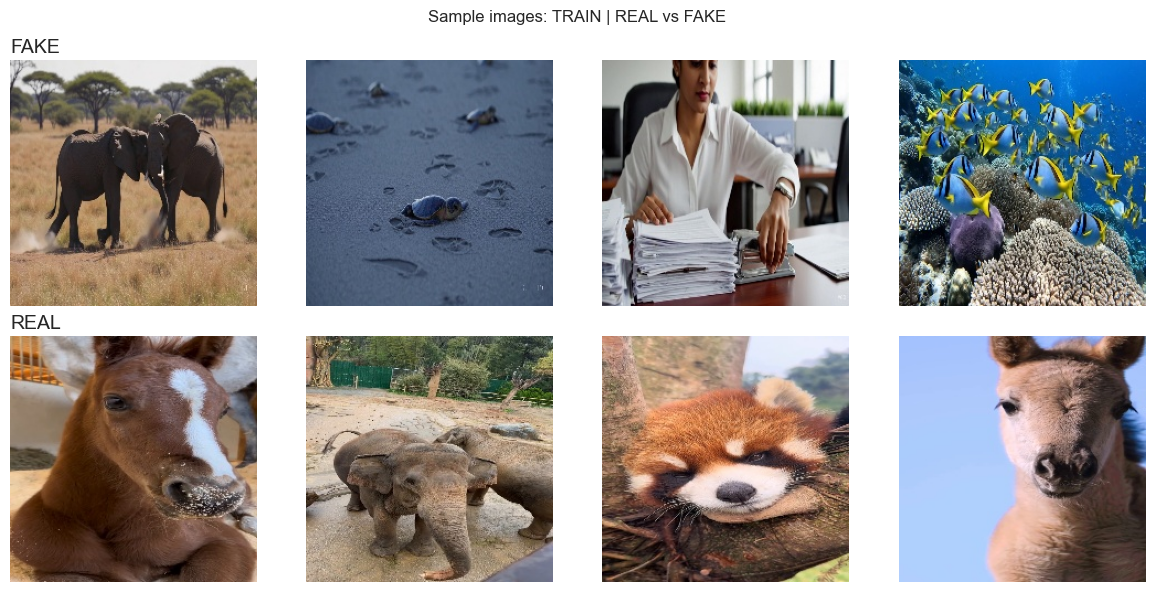

In [ ]:
show_sample_grid(CONFIG["SPLIT_DIR"], split="train")

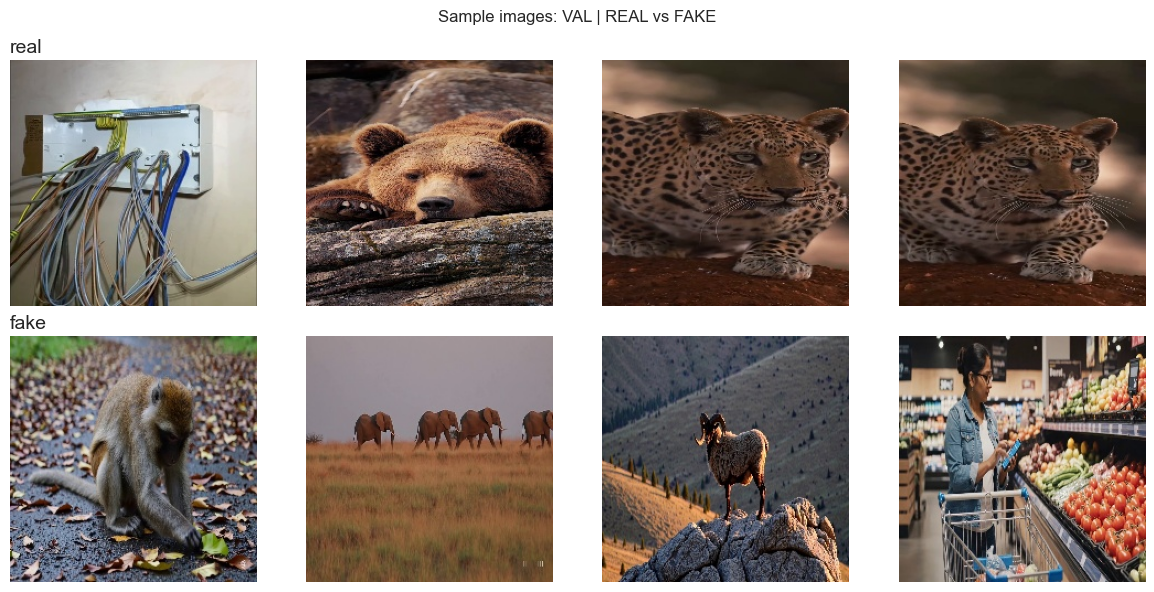

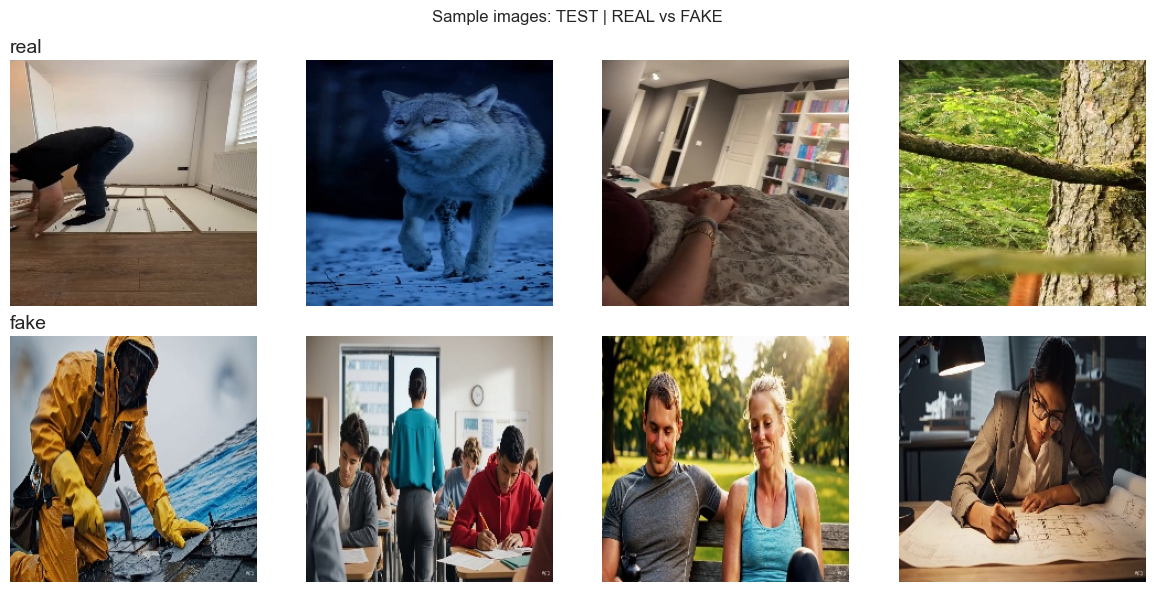

In [ ]:
show_sample_grid(CONFIG["SPLIT_DIR"], split="val")
show_sample_grid(CONFIG["SPLIT_DIR"], split="test")

## 7. เตรียมข้อมูลสำหรับโมเดล (Data Pipeline & Augmentation)

- ใช้ `tf.keras.utils.image_dataset_from_directory` โหลดภาพเป็น `tf.data.Dataset`
- ใช้ **data augmentation** (flip, rotation, zoom, contrast) เฉพาะบนชุด train เพื่อลด overfitting
- แต่ละโมเดล transfer learning มีฟังก์ชัน `preprocess_input` เฉพาะของตัวเอง (เช่น scale เป็น [-1,1] หรือ [0,1] ต่างกัน)
  จึงสร้างฟังก์ชัน `build_datasets(preprocess_fn)` ที่รับ preprocessing function มาประกอบเข้ากับ pipeline ให้อัตโนมัติ

In [ ]:
print("class_names (index 0, 1 ตามลำดับนี้):", train_ds.class_names)
# ควรได้ ['REAL', 'FAKE']

NameError: name 'train_ds' is not defined

## 8. โมเดล



| กลุ่ม | โมเดล | แนวคิด |
|---|---|---|
| Transfer learning (deep residual) | **ResNet50** | ใช้ skip-connection ช่วยฝึกโมเดลลึกได้ดี |

โมเดล transfer learning ใช้ backbone ที่ผ่านการ pre-train บน ImageNet, ตัดชั้น classifier เดิมออก,
แล้วต่อ **head ใหม่**: `GlobalAveragePooling2D -> Dropout -> Dense(1, sigmoid)` สำหรับ binary classification (REAL=0 / FAKE=1)

In [ ]:
def build_baseline_cnn(img_size):
    inputs = keras.Input(shape=(img_size, img_size, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs, name="Baseline_CNN")
    return model


def build_transfer_model(base_constructor, img_size, name):
    """สร้างโมเดล transfer learning ทั่วไป: base (frozen) + head ใหม่"""
    base_model = base_constructor(
        include_top=False, weights="imagenet",
        input_shape=(img_size, img_size, 3),
    )
    base_model.trainable = False  # เฟสแรก: freeze backbone ทั้งหมด ฝึกแค่ head

    inputs = keras.Input(shape=(img_size, img_size, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs, name=name)
    return model, base_model


# ทะเบียนโมเดลทั้งหมดที่จะทดลอง: name -> (builder_fn, preprocess_fn, is_transfer)
MODEL_REGISTRY = {
    "ResNet50": {
        "build": lambda: build_transfer_model(resnet50.ResNet50, CONFIG["IMG_SIZE"], "ResNet50"),
        "preprocess": resnet50.preprocess_input,
        "is_transfer": True,
    }
}

print("โมเดลที่จะทดลองทั้งหมด:", list(MODEL_REGISTRY.keys()))

โมเดลที่จะทดลองทั้งหมด: ['ResNet50']


## 9. ฟังก์ชันฝึกและประเมินผลโมเดล (Training & Evaluation Utilities)

แนวทางการฝึกโมเดล transfer learning แบ่งเป็น 2 เฟส:
1. **Head training**: freeze backbone ทั้งหมด ฝึกเฉพาะ head ใหม่ (เร็ว ป้องกันไม่ให้ backbone เพี้ยนตั้งแต่ต้น)
2. **Fine-tuning**: unfreeze backbone บางส่วน (ชั้นบน ๆ) แล้วฝึกต่อด้วย learning rate ต่ำมาก เพื่อปรับ feature ให้เข้ากับ dataset นี้

สำหรับ Baseline CNN (ฝึกจากศูนย์) จะฝึกยาวไปเลยโดยไม่มีเฟส fine-tune

ทุกโมเดลใช้ **EarlyStopping** (เฝ้าดู val_loss), **ReduceLROnPlateau** และ **ModelCheckpoint** (เก็บโมเดลที่ val_loss ต่ำสุด)

การประเมินผลใช้ **FAKE เป็น positive class (label=1)** และวัดด้วย Accuracy, Precision, Recall, F1-score, ROC-AUC

In [ ]:
def get_positive_index(class_names):
    """หา index ของคลาส FAKE ใน class_names (image_dataset_from_directory เรียงตามตัวอักษร)"""
    return class_names.index("FAKE")


def make_callbacks(ckpt_path):
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7),
        callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_loss", save_best_only=True),
    ]


def get_true_and_prob(model, dataset):
    """รวบรวม label จริง (y_true) และความน่าจะเป็น (y_prob) จากทั้ง dataset"""
    y_true, y_prob = [], []
    for x_batch, y_batch in dataset:
        probs = model.predict(x_batch, verbose=0).ravel()
        y_prob.extend(probs.tolist())
        y_true.extend(y_batch.numpy().ravel().tolist())
    return np.array(y_true), np.array(y_prob)


def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }


def train_and_evaluate(model_name, config_entry, verbose=1):
    """pipeline ครบวงจร: สร้าง dataset -> build model -> ฝึก (+fine-tune ถ้าเป็น transfer model) -> ประเมินผลบน test set"""
    print(f"\n{'=' * 70}\n เริ่มฝึกโมเดล: {model_name}\n{'=' * 70}")

    train_ds, val_ds, test_ds, class_names = build_datasets(config_entry["preprocess"])
    pos_idx = get_positive_index(class_names)
    # ถ้า FAKE ไม่ได้เป็น label=1 (pos_idx==0) ให้กลับค่า y_true ตอนคำนวณ metrics
    flip_labels = (pos_idx == 0)

    model, base_model = config_entry["build"]()
    model.compile(
        optimizer=keras.optimizers.Adam(CONFIG["LEARNING_RATE"]),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )

    ckpt_path = CONFIG["OUTPUT_DIR"] / f"{model_name}_best.keras"
    history_head = model.fit(
        train_ds, validation_data=val_ds,
        epochs=CONFIG["EPOCHS_HEAD"],
        callbacks=make_callbacks(ckpt_path),
        verbose=verbose,
    )

    history_finetune = None
    if config_entry["is_transfer"] and base_model is not None:
        # เฟส fine-tune: unfreeze ~30% ของ layer บนสุดของ backbone
        base_model.trainable = True
        n_layers = len(base_model.layers)
        freeze_until = int(n_layers * 0.7)
        for layer in base_model.layers[:freeze_until]:
            layer.trainable = False

        model.compile(
            optimizer=keras.optimizers.Adam(CONFIG["FINETUNE_LR"]),
            loss="binary_crossentropy",
            metrics=["accuracy", keras.metrics.AUC(name="auc")],
        )
        history_finetune = model.fit(
            train_ds, validation_data=val_ds,
            epochs=CONFIG["EPOCHS_FINETUNE"],
            callbacks=make_callbacks(ckpt_path),
            verbose=verbose,
        )

    # โหลด weight ที่ดีที่สุด (val_loss ต่ำสุด) กลับมาก่อนประเมินผล
    model.load_weights(ckpt_path)

    y_true, y_prob = get_true_and_prob(model, test_ds)
    if flip_labels:
        y_true = 1 - y_true
        y_prob = 1 - y_prob
    metrics_dict = compute_metrics(y_true, y_prob)
    metrics_dict["model"] = model_name

    print(f"\nผลลัพธ์บน Test set ของ {model_name}:")
    for k, v in metrics_dict.items():
        if k != "model":
            print(f"  {k:10s}: {v:.4f}")

    result = {
        "model_name": model_name,
        "model": model,
        "history_head": history_head.history,
        "history_finetune": history_finetune.history if history_finetune else None,
        "y_true": y_true,
        "y_prob": y_prob,
        "metrics": metrics_dict,
    }
    return result

## 10. ฝึกและเปรียบเทียบโมเดลทั้งหมด (Train All Models)

รันฝึกทีละโมเดลตามลำดับใน `MODEL_REGISTRY` แล้วเก็บผลลัพธ์ทั้งหมดไว้ใน dict `all_results`

> ⏱️ **คำเตือนเรื่องเวลา:** การฝึก 6 โมเดล (โดยเฉพาะบน CPU) อาจใช้เวลานาน แนะนำให้รันบน GPU
> หากต้องการทดสอบโค้ดอย่างรวดเร็วก่อน ให้ลดค่า `EPOCHS_HEAD` / `EPOCHS_FINETUNE` ใน CONFIG ลงชั่วคราว
> หรือลดจำนวนโมเดลใน `MODEL_REGISTRY` ที่จะรัน (แก้ลิสต์ `MODELS_TO_RUN` ด้านล่าง)

In [ ]:
print("SPLIT_DIR:", CONFIG["SPLIT_DIR"])
print("CLASS_NAMES:", CONFIG["CLASS_NAMES"])

for split in ["train", "val", "test"]:
    path = CONFIG["SPLIT_DIR"] / split
    print(split, "=>", [x.name for x in path.iterdir() if x.is_dir()])

SPLIT_DIR: data
CLASS_NAMES: ['FAKE', 'REAL']
train => ['FAKE', 'REAL']
val => ['FAKE', 'REAL']
test => ['FAKE', 'REAL']


In [ ]:
import os

MODEL_SAVE_DIR = "/content/saved_models"
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

MODELS_TO_RUN = list(MODEL_REGISTRY.keys())

all_results = {}

for model_name in MODELS_TO_RUN:
    keras.backend.clear_session()
    result = train_and_evaluate(
        model_name,
        MODEL_REGISTRY[model_name],
        verbose=1
    )
    all_results[model_name] = result

    # SAVE MODEL
    model = result["model"]
    model.save(f"{MODEL_SAVE_DIR}/{model_name}.keras")
    gc.collect()
print("\n\nฝึกครบทุกโมเดลแล้ว:", list(all_results.keys()))


 เริ่มฝึกโมเดล: ResNet50
Found 16800 files belonging to 2 classes.
Found 3600 files belonging to 2 classes.
Found 3600 files belonging to 2 classes.
class_names (label 0/1 ตามลำดับนี้): ['FAKE', 'REAL']
94765736/94765736 [==============================] - 6s 0us/step
Epoch 1/8
525/525 [==============================] - 183s 313ms/step - loss: 0.3461 - accuracy: 0.8525 - auc: 0.9264 - val_loss: 0.3302 - val_accuracy: 0.8533 - val_auc: 0.9469 - lr: 0.0010
Epoch 2/8
525/525 [==============================] - 121s 228ms/step - loss: 0.2411 - accuracy: 0.9032 - auc: 0.9646 - val_loss: 0.3005 - val_accuracy: 0.8767 - val_auc: 0.9516 - lr: 0.0010
Epoch 3/8
525/525 [==============================] - 114s 214ms/step - loss: 0.2191 - accuracy: 0.9114 - auc: 0.9709 - val_loss: 0.3168 - val_accuracy: 0.8725 - val_auc: 0.9537 - lr: 0.0010
Epoch 4/8
525/525 [==============================] - 119s 223ms/step - loss: 0.2066 - accuracy: 0.9171 - auc: 0.9739 - val_loss: 0.3505 - val_accuracy: 0.8678 - 

In [ ]:
from pathlib import Path

print("MODEL_SAVE_DIR =", MODEL_SAVE_DIR)
print("Absolute path  =", Path(MODEL_SAVE_DIR).resolve())

print("\nFiles:")
for f in Path(MODEL_SAVE_DIR).glob("*.keras"):
    print(f.resolve())

MODEL_SAVE_DIR = /content/saved_models
Absolute path  = C:\content\saved_models

Files:
C:\content\saved_models\ResNet50.keras


## 11. สรุปผลและเปรียบเทียบประสิทธิภาพ (Results Comparison)

รวบรวมค่า Accuracy, Precision, Recall, F1-score, ROC-AUC ของทุกโมเดลมาไว้ในตารางเดียว
แล้ววาดกราฟเปรียบเทียบ, กราฟ training curve, confusion matrix และ ROC curve

In [ ]:
results_df = pd.DataFrame([r["metrics"] for r in all_results.values()])
results_df = results_df[["model", "accuracy", "precision", "recall", "f1", "roc_auc"]]
results_df = results_df.sort_values("f1", ascending=False).reset_index(drop=True)
results_df

,model,accuracy,precision,recall,f1,roc_auc
0,ResNet50,0.920556,0.891417,0.957778,0.923407,0.978339


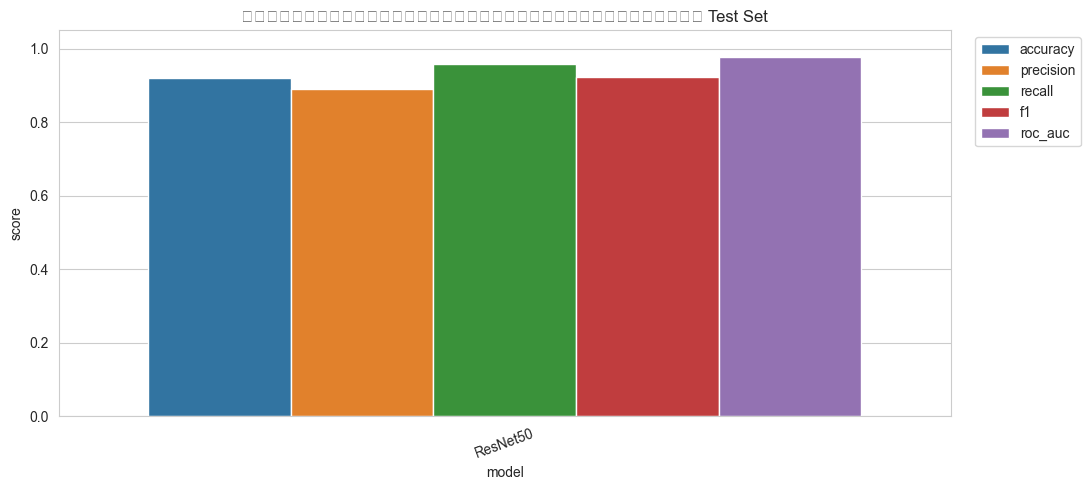


🏆 โมเดลที่ดีที่สุด (ตาม F1-score) คือ: ResNet50


In [ ]:
metrics_to_plot = ["accuracy", "precision", "recall", "f1", "roc_auc"]
plot_df = results_df.melt(id_vars="model", value_vars=metrics_to_plot,
                           var_name="metric", value_name="score")

plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="model", y="score", hue="metric")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.title("เปรียบเทียบประสิทธิภาพของแต่ละโมเดลบน Test Set")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

BEST_MODEL_NAME = results_df.iloc[0]["model"]
print(f"\n🏆 โมเดลที่ดีที่สุด (ตาม F1-score) คือ: {BEST_MODEL_NAME}")

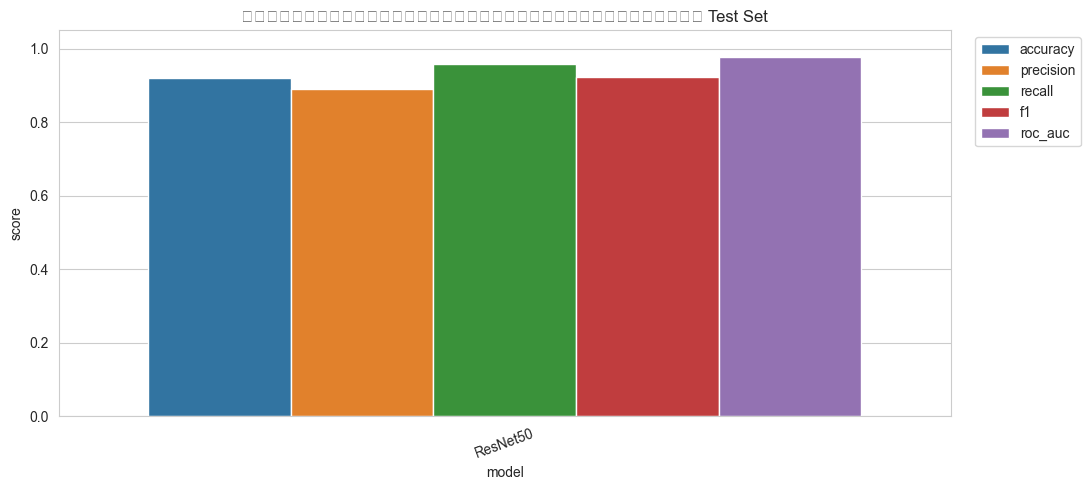

In [ ]:
metrics_to_plot = ["accuracy", "precision", "recall", "f1", "roc_auc"]
plot_df = results_df.melt(id_vars="model", value_vars=metrics_to_plot,
                           var_name="metric", value_name="score")

plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="model", y="score", hue="metric")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.title("เปรียบเทียบประสิทธิภาพของแต่ละโมเดลบน Test Set")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

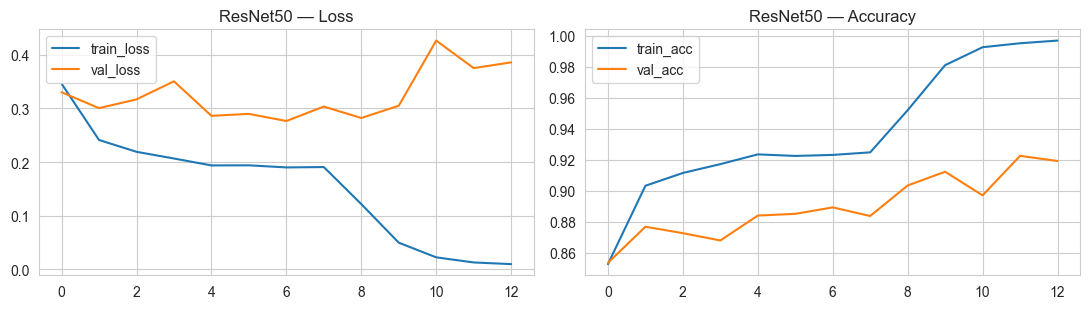

In [ ]:
# กราฟ training curve (loss / accuracy) ของทุกโมเดล — รวมเฟส head training + fine-tuning
n_models = len(all_results)
fig, axes = plt.subplots(n_models, 2, figsize=(11, 3.2 * n_models))
if n_models == 1:
    axes = axes.reshape(1, -1)

for i, (name, r) in enumerate(all_results.items()):
    h = dict(r["history_head"])
    if r["history_finetune"]:
        for k, v in r["history_finetune"].items():
            h[k] = h.get(k, []) + v

    axes[i, 0].plot(h["loss"], label="train_loss")
    axes[i, 0].plot(h["val_loss"], label="val_loss")
    axes[i, 0].set_title(f"{name} — Loss")
    axes[i, 0].legend()

    axes[i, 1].plot(h["accuracy"], label="train_acc")
    axes[i, 1].plot(h["val_accuracy"], label="val_acc")
    axes[i, 1].set_title(f"{name} — Accuracy")
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

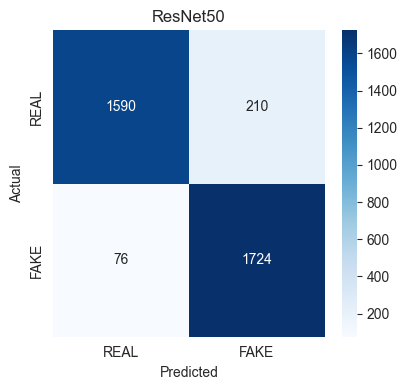

In [ ]:
# Confusion matrix ของทุกโมเดล
n_models = len(all_results)
n_cols = 1
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for i, (name, r) in enumerate(all_results.items()):
    y_pred = (r["y_prob"] >= 0.5).astype(int)
    cm = confusion_matrix(r["y_true"], y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["REAL", "FAKE"], yticklabels=["REAL", "FAKE"], ax=axes[i])
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

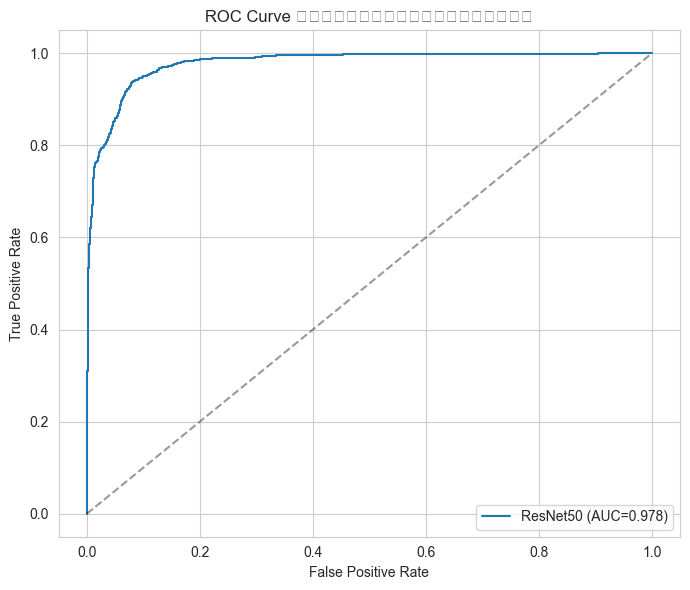

In [ ]:
# ROC curve ของทุกโมเดลซ้อนกันในกราฟเดียว
plt.figure(figsize=(7, 6))
for name, r in all_results.items():
    fpr, tpr, _ = roc_curve(r["y_true"], r["y_prob"])
    auc_val = r["metrics"]["roc_auc"]
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve เปรียบเทียบทุกโมเดล")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Classification report ของโมเดลที่ดีที่สุด
best_result = all_results[BEST_MODEL_NAME]
best_pred = (best_result["y_prob"] >= 0.5).astype(int)
print(f"Classification report — {BEST_MODEL_NAME}\n")
print(classification_report(best_result["y_true"], best_pred, target_names=["REAL", "FAKE"]))

Classification report — ResNet50

              precision    recall  f1-score   support

        REAL       0.95      0.88      0.92      1800
        FAKE       0.89      0.96      0.92      1800

    accuracy                           0.92      3600
   macro avg       0.92      0.92      0.92      3600
weighted avg       0.92      0.92      0.92      3600



## 13. จากการจำแนกภาพ สู่การตรวจจับวิดีโอจริง (Video-level Detection)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# VIDEO AI vs REAL DETECTION
# ตรวจวิดีโอทั้งหมดใน unseen/real และ unseen/fake
# ============================================================
import os
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
# ============================================================
# 1. ตั้งค่าโฟลเดอร์
# ============================================================
UNSEEN_FOLDER = Path(
    "/content/drive/MyDrive/Colab Notebooks/project/data/unseen_vdo"
)
N_FRAMES = 16
THRESHOLD = 0.5
# ============================================================
# 1.5 โหลด ResNet50 ที่บันทึกไว้
# ============================================================
import tensorflow as tf

MODEL_PATH = (
    "/content/drive/MyDrive/Colab Notebooks/project/model/ResNet50_best_image.keras"
)

BEST_MODEL_NAME = "ResNet50"

# โหลดโมเดล
loaded_model = tf.keras.models.load_model(
    MODEL_PATH
)

# ใส่โมเดลเข้า all_results
all_results = {
    BEST_MODEL_NAME: {
        "model": loaded_model,
        "flip_labels": True
    }
}

print("=" * 70)
print("MODEL LOADED")
print("=" * 70)
print(f"Model : {BEST_MODEL_NAME}")
print(f"Path  : {MODEL_PATH}")
print("โหลด ResNet50_best.keras สำเร็จ")
print("=" * 70)

MODEL LOADED
Model : ResNet50
Path  : /content/drive/MyDrive/Colab Notebooks/project/model/ResNet50_best_image.keras
โหลด ResNet50_best.keras สำเร็จ


In [ ]:
"""
predict_video.py
==================
รันบน Google Colab: โหลดโมเดล ResNet50_best.keras แล้วทำนายวิดีโอ unseen
จาก Google Drive (ทีละไฟล์หรือทั้งโฟลเดอร์) ด้วย pipeline เดียวกับที่ผ่าน
canary test มาแล้ว (canary_check_ready.py)

ก่อนรัน แก้ให้ตรงกับของคุณ:
  1) MODEL_PATH        -> path ไฟล์ ResNet50_best.keras
  2) UNSEEN_DIR         -> โฟลเดอร์วิดีโอที่ต้องการทำนาย (ไม่ต้องมี real/fake ในชื่อ)
  3) CLASS_INDEX_FAKE   -> ใช้ค่าเดียวกับที่ยืนยันถูกต้องแล้วจาก canary test
  4) VOTE_THRESHOLD     -> เกณฑ์ตัดสิน (ดูคำอธิบายด้านล่าง)
"""

import os
import glob
from pathlib import Path
import csv
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

# ------------------------------------------------------------------
# 1) mount Google Drive
# ------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

# ------------------------------------------------------------------
# 2) ตั้งค่า — ต้องตรงกับตอน canary test เป๊ะๆ
# ------------------------------------------------------------------
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/project/model/ResNet50_best_image.keras"
UNSEEN_DIR = "/content/drive/MyDrive/Colab Notebooks/project/data/unseen_vdo"
# OUTPUT_CSV = "/content/drive/MyDrive/path/to/predictions.csv"

IMG_SIZE = (224, 224)
N_FRAMES = 16                 # จำนวนเฟรมที่สุ่มต่อวิดีโอ (ค่าเดียวกับ canary test)
CLASS_INDEX_FAKE = 0          # ใช้ค่าที่ยืนยันถูกต้องแล้วจาก canary_check_ready.py

# วิธีตัดสินระดับวิดีโอ: ใช้ "ค่าเฉลี่ย probability ของทุกเฟรม" (soft-voting)
# เทียบกับ threshold เดียว แทนการนับจำนวนเฟรมดิบๆ เพราะ robust กว่ากับวิดีโอ
# ที่ความยาว/จำนวนเฟรมต่างกัน — ปรับตัวเลขนี้ได้จากผลบน validation set จริง
VOTE_THRESHOLD = 0.55

VIDEO_EXTS = (".mp4", ".mov", ".avi", ".webm")


# ------------------------------------------------------------------
# 3) โหลดโมเดล
# ------------------------------------------------------------------
print("กำลังโหลดโมเดล ...")
model = tf.keras.models.load_model(MODEL_PATH)
print("โหลดโมเดลสำเร็จ:", MODEL_PATH)


def extract_frames(video_path: str, n_frames: int = N_FRAMES):
    """สุ่มเฟรมแบบกระจายทั่ววิดีโอ (uniform sampling) เลี่ยงเฟรมต้น/ท้ายคลิป"""
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = []
    if total <= 0:
        cap.release()
        return frames
    idxs = [int(total * f / (n_frames + 1)) for f in range(1, n_frames + 1)]
    for idx in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if not ok:
            continue
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, IMG_SIZE)
        frames.append(frame)
    cap.release()
    return frames


def predict_video(video_path: str):
    """
    ทำนายวิดีโอ 1 ไฟล์ คืนค่า dict:
      frame_probs   -> prob(fake) รายเฟรม (ไว้ debug/วิเคราะห์เพิ่มได้)
      mean_prob     -> ค่าเฉลี่ย (ใช้ตัดสินใจ)
      label         -> "fake" หรือ "real"
      n_frames_used -> จำนวนเฟรมที่ใช้จริง (บางคลิปอาจอ่านเฟรมได้ไม่ครบ)
    """
    frames = extract_frames(video_path)
    if not frames:
        raise ValueError(f"อ่านเฟรมไม่ได้ (ไฟล์เสียหรือ path ผิด): {video_path}")

    batch = np.array(frames).astype("float32")
    batch = preprocess_input(batch)
    preds = model.predict(batch, verbose=0)

    if preds.shape[-1] == 1:
        raw = preds[:, 0]
        frame_probs = raw if CLASS_INDEX_FAKE == 1 else (1.0 - raw)
    else:
        frame_probs = preds[:, CLASS_INDEX_FAKE]

    mean_prob = float(np.mean(frame_probs))
    label = "fake" if mean_prob >= VOTE_THRESHOLD else "real"

    return {
        "frame_probs": frame_probs.tolist(),
        "mean_prob": mean_prob,
        "label": label,
        "n_frames_used": len(frames),
    }


# ------------------------------------------------------------------
# 4) รันกับทุกวิดีโอใน UNSEEN_DIR (ค้นลึกเข้าไปในโฟลเดอร์ย่อยด้วย เช่น
#    UNSEEN_DIR/real/*.mp4 และ UNSEEN_DIR/fake/*.mp4)
# ------------------------------------------------------------------
video_paths = sorted(
    str(p) for p in Path(UNSEEN_DIR).rglob("*")
    if p.suffix.lower() in VIDEO_EXTS
)
print(f"พบวิดีโอทั้งหมด {len(video_paths)} ไฟล์ใน {UNSEEN_DIR} (รวม subfolder)\n")


def true_label_from_path(path: str):
    """เดา label จริงจากชื่อโฟลเดอร์แม่ (.../real/xxx.mp4 หรือ .../fake/xxx.mp4)
    ถ้าไม่เจอคำว่า real/fake ในโฟลเดอร์เลย จะคืนค่า None (แปลว่าไม่รู้ label จริง)"""
    parts = [p.lower() for p in Path(path).parts]
    if "real" in parts:
        return "real"
    if "fake" in parts:
        return "fake"
    return None


rows = []
for p in video_paths:
    name = os.path.basename(p)
    true_label = true_label_from_path(p)
    try:
        result = predict_video(p)
        rows.append({
            "filename": name,
            "true_label": true_label,
            "mean_prob_fake": round(result["mean_prob"], 4),
            "predicted_label": result["label"],
            "n_frames_used": result["n_frames_used"],
        })
        mark = "" if true_label is None else ("✅" if true_label == result["label"] else "❌")
        print(f"{name:30s} true={str(true_label):6s} mean_prob(fake)={result['mean_prob']:.3f}  -> {result['label']}  {mark}")
    except Exception as e:
        print(f"❌ ERROR on {name}: {e}")
        rows.append({
            "filename": name,
            "true_label": true_label,
            "mean_prob_fake": None,
            "predicted_label": "ERROR",
            "n_frames_used": 0,
        })

# บันทึกเป็น CSV
# with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
#     writer = csv.DictWriter(
#         f, fieldnames=["filename", "true_label", "mean_prob_fake", "predicted_label", "n_frames_used"]
#     )
#     writer.writeheader()
#     writer.writerows(rows)

# print(f"\nบันทึกผลลัพธ์ที่: {OUTPUT_CSV}")

# สรุปจำนวนที่ทายได้
n_fake = sum(1 for r in rows if r["predicted_label"] == "fake")
n_real = sum(1 for r in rows if r["predicted_label"] == "real")
n_err = sum(1 for r in rows if r["predicted_label"] == "ERROR")
print(f"\nสรุปการทาย: fake={n_fake}  real={n_real}  error={n_err}  จากทั้งหมด {len(rows)} ไฟล์")

# ------------------------------------------------------------------
# 5) ถ้ารู้ label จริง (มาจากชื่อโฟลเดอร์) ให้คำนวณ accuracy + confusion matrix
# ------------------------------------------------------------------
labeled_rows = [r for r in rows if r["true_label"] is not None and r["predicted_label"] != "ERROR"]
if labeled_rows:
    tp = sum(1 for r in labeled_rows if r["true_label"] == "fake" and r["predicted_label"] == "fake")
    tn = sum(1 for r in labeled_rows if r["true_label"] == "real" and r["predicted_label"] == "real")
    fp = sum(1 for r in labeled_rows if r["true_label"] == "real" and r["predicted_label"] == "fake")
    fn = sum(1 for r in labeled_rows if r["true_label"] == "fake" and r["predicted_label"] == "real")
    total = tp + tn + fp + fn
    acc = (tp + tn) / total if total else 0.0

    print("\n===== ผลประเมินเทียบกับ label จริง (จากชื่อโฟลเดอร์) =====")
    print(f"Accuracy: {acc*100:.1f}%  ({tp+tn}/{total})")
    print("Confusion matrix:")
    print(f"                 predicted real   predicted fake")
    print(f"  actual real         {tn:5d}            {fp:5d}")
    print(f"  actual fake         {fn:5d}            {tp:5d}")

    if fp > tn:  # real ถูกทายเป็น fake มากกว่าที่ทายถูก -> น่าสงสัยว่า label สลับ
        print("\n*** เตือน: real ถูกทายผิดเป็น fake มากผิดปกติ ถ้า accuracy ต่ำกว่า 50% "
              "มาก ให้สงสัยว่า CLASS_INDEX_FAKE ยังตั้งค่าผิดอยู่ (label กลับด้าน) ***")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
กำลังโหลดโมเดล ...
โหลดโมเดลสำเร็จ: /content/drive/MyDrive/Colab Notebooks/project/model/ResNet50_best_image.keras
พบวิดีโอทั้งหมด 113 ไฟล์ใน /content/drive/MyDrive/Colab Notebooks/project/data/unseen_vdo (รวม subfolder)

fake1.mp4                      true=fake   mean_prob(fake)=0.636  -> fake  ✅
fake10.mov                     true=fake   mean_prob(fake)=0.101  -> real  ❌
fake11.mp4                     true=fake   mean_prob(fake)=0.941  -> fake  ✅
fake12.mp4                     true=fake   mean_prob(fake)=0.596  -> fake  ✅
fake13.mp4                     true=fake   mean_prob(fake)=0.083  -> real  ❌
fake14.mp4                     true=fake   mean_prob(fake)=0.722  -> fake  ✅
fake15.mp4                     true=fake   mean_prob(fake)=0.617  -> fake  ✅
fake16.mp4                     true=fake   mean_prob(fake)=0.865  -> fake  ✅
fake17.mp4                     tr